# W09B · A · 뉴스 분류 파인튜닝

2026-10-28 · 주교재6.1–6.3 · CPU · 패키지0.1.15

같은 뉴스에서 클래스 정답·손실·가중치 갱신·평가를 연결합니다. CPU에서 실제 DistilBERT를 학습하며 이전 노트북 없이 시작합니다.

Drive에 새 사본을 저장하고 첫 셀부터 실행하세요. A/B는 독립적입니다. API 키·개인 파일 업로드·유료 GPU가 필수가 아닙니다. 최초 모델은 A약269 MB/B약541 MB, 데이터약20 MB와 의존성을 준비하고 캐시를 재사용합니다.

[한 장 지도](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/course/notion/w09b/w09b-map.md) · [기록지](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/course/notion/w09b/w09b-workbook.md) · [API 정의와 입력·출력](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)

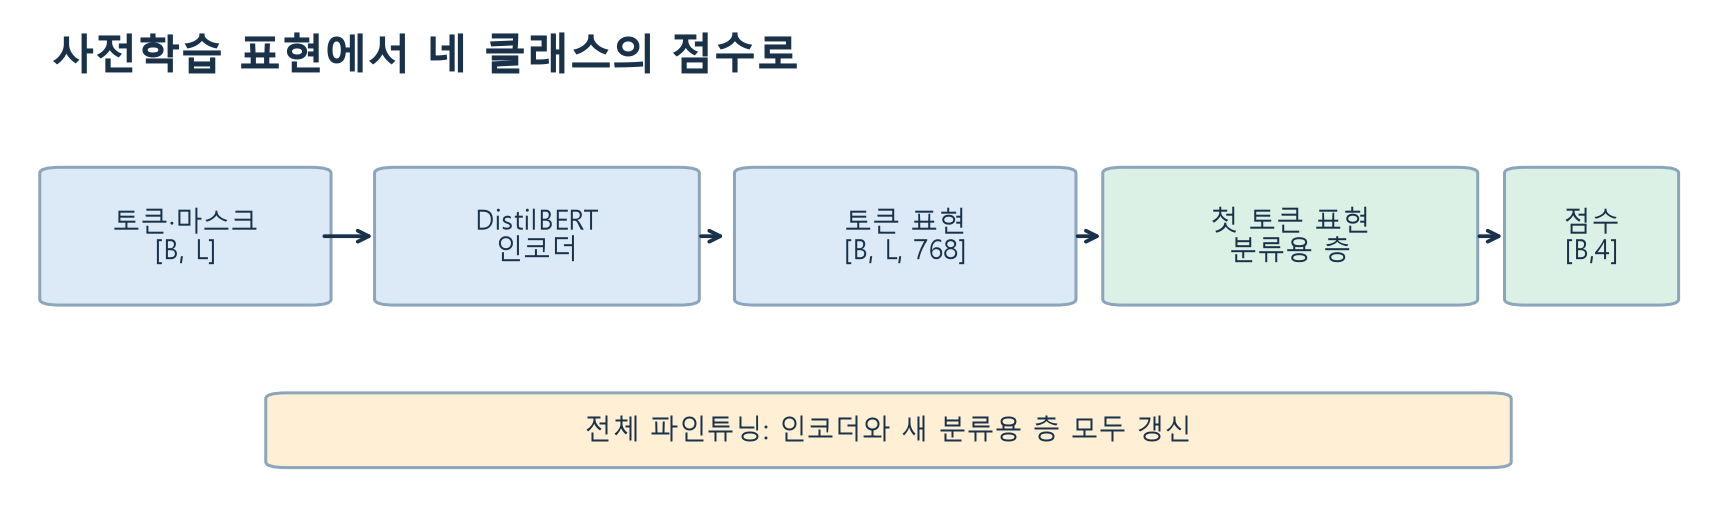

그림의 구조를 실제 출력과 대조하세요. 모든 문제는 예상·실행·근거 설명을 포함합니다. 문제용 빈칸은 기본 실험 변수를 바꾸지 않아, 아직 답하지 못해도 다음 기본 셀을 실행할 수 있습니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w09b/course/notion/w09b/assets/03-encoder-head.png)


## 0. 설치와 준비

첫 셀은 고정한 수업 패키지를 설치합니다. `prepare_text_runtime()`은 별도 자식 Python으로 텍스트 모델 import를 점검하며, 설치돼 있지만 import가 실패한 선택 영상·음성 패키지만 현재 런타임에서 복구합니다. 정상 패키지와 torch는 유지합니다. 이전 모듈을 불러온 뒤 설치 버전을 바꿨다면 런타임을 재시작합니다.

모델/데이터 다운로드 실패는 오류로 표시합니다. 연결을 복구한 뒤 준비 셀을 다시 실행하면 완전한 캐시를 재사용합니다. 개인 PC의 비공개 경로를 Colab 입력으로 사용하지 않습니다.


In [ ]:
import sys, subprocess, os, json, math, time, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w09b'
try:
    ready=all(version(p)==v for p,v in [('luna-genai','0.1.15'),('datasets','4.8.5'),('transformers','5.15.1'),('gradio','6.26.0')])
except PackageNotFoundError:
    ready=False
if not ready:
    if 'luna_genai' in sys.modules:
        raise RuntimeError('이전 버전이 메모리에 남아 있습니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
    package=str(Path('src').resolve()) if Path('src/pyproject.toml').exists() else f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed_optional=prepare_text_runtime(repair_optional=True)
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from luna_genai.finetuning import FineTuningLab,load_news,text_key,classification_metrics,cross_entropy,causal_batch,target_table,instruction_record
from luna_genai.finetuning_app import build_finetuning_app,classification_view,generation_view,instruction_view
torch.set_num_threads(2)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
DEVICE='cpu'  # GPU 확장은 사용 가능한 무료 장치를 직접 선택한 경우에만 cuda로 변경
print('Python',sys.version.split()[0],'package',version('luna-genai'),'device',DEVICE,'CUDA available',torch.cuda.is_available())
print('정상적인 선택 패키지는 유지합니다. 제거한 비호환 선택 패키지:',removed_optional)


## 1. 데이터와 학습목표

[`load_news()`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)는 실제 AG News 고정 revision에서 클래스별 표본을 준비합니다. train/validation은 원 train에서, test는 원 test에서 가져오며 정규화된 중복 텍스트를 분리합니다. 반환값은 세 분할의 행 사전 목록과 provenance입니다. 다운로드·캐시 쓰기가 있을 수 있습니다.


In [ ]:
news=load_news(train_per_class=64,validation_per_class=32,test_per_class=32)
display(pd.DataFrame(news['provenance']['rows'].items(),columns=['split','documents']))
print(news['provenance'])
display(pd.DataFrame([{'source_id':r['id'],'label':r['label'],'text_excerpt':r['text'][:100]} for r in news['train'][:2]]))


### A1 · 필수

같은 뉴스에서 프롬프트만 바꾼 분류와 가중치를 학습한 분류는 어떻게 다를까요? 실행 전 예상과, 학습 효과를 확인하려면 고정할 조건을 적으세요. 마지막에는 제품 리뷰 분류나 제목 생성으로 입력·정답·손실·갱신 대상·평가를 옮겨 설명하세요.

**힌트:** 입력 문자열의 변화와 optimizer가 바꾸는 대상을 구별합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 2. 실제 분류 모델과 작은 손실 계산

[`FineTuningLab('classification')`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)는 고정된 사전학습 인코더와 새 네 클래스 분류용 층을 준비합니다. 기본적으로 둘 다 학습 대상입니다. 새 분류용 층의 초기화 메시지는 예상되며 학습 완료를 뜻하지 않습니다. 객체의 state는 장치·revision·학습 단계·파라미터 수를 반환합니다.

문장당 정답 확률을 $p$라 하면 손실은 $-\log p$입니다. 배치는 문장별 손실을 평균냅니다.


In [ ]:
lab=FineTuningLab('classification',device=DEVICE,seed=42,max_length=64)
display(lab.state())
a2_loss=None  # 연습용 답; 기본 실행에는 사용하지 않습니다.


### A2 · 확장

설명용 클래스 확률이 [0.1,0.7,0.1,0.1]이고 정답 ID가1이면 손실을 계산하세요. 정답 ID를0으로 바꾸면 어떻게 되나요?

**힌트:** 정답 위치의 확률을 선택한 뒤 자연로그를 씁니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 3. 한 배치의 실제 크기·마스크·출력

아래 두 문장은 수업에서 직접 작성한 구조 관찰용 예문입니다. tokenizer가 실제 토큰 ID와 마스크를 만들고, model은 은닉 표현과 네 클래스 logits를 반환합니다. `**batch`는 사전의 키를 이름 있는 인자로 전달합니다. `inference_mode`는 이 관찰에서 기울기 계산을 끕니다.


In [ ]:
examples=[{'text':'Markets rallied.','label':2},{'text':'The football team won the final match after extra time.','label':1}]
batch=lab.batch(examples)
display(pd.DataFrame([{'name':k,'shape':str(tuple(v.shape)),'dtype':str(v.dtype)} for k,v in batch.items()]))
print('IDs:',batch['input_ids']);print('mask:',batch['attention_mask']);print('labels:',batch['labels'])
with torch.inference_mode():
    inspected=lab.model(**batch,output_hidden_states=True)
print('hidden:',tuple(inspected.hidden_states[-1].shape),'logits:',tuple(inspected.logits.shape))
display(pd.DataFrame(inspected.logits.float().softmax(-1).cpu().numpy(),columns=news['provenance']['classes']))


### A3 · 필수

B=2인 위 배치에서 분류 labels의 개수, hidden/logits의 크기와 padding 위치를 설명하세요. 입력 길이를 줄이면 어떤 정보가 잘리는지도 예상하세요.

**힌트:** mask0과 labels의 축 수를 함께 봅니다. L은 두 문장의 패딩 후 최대 길이입니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 4. 학습 전 평가 → 실제 갱신 → 같은 데이터로 평가

`fit(rows,steps,batch_size,learning_rate)`는 현재 객체의 가중치를 계속 갱신합니다. 고정 학습률 AdamW, weight decay0.01, 기울기 clipping1.0을 사용합니다. 다시 호출하면 같은 시작점의 새 실험이 아니라 **이어서 학습**합니다. 설정 비교에는 같은 seed의 새 객체를 준비합니다.

여기서는 CPU 측정 후 정한32회·batch2를 사용합니다. 매 단계 loss와 갱신 전 기울기 norm을 확인하고 같은 validation을 전후 비교합니다. 전체 데이터 한 epoch 학습이나 교재의 고성능 재현 실험으로 해석하지 않습니다.


### A4 · 필수

다음 두 오류를 설명하고 올바른 한 단계의 순서를 쓰세요: ① loss.backward()만 실행 ② 현재 배치의 backward 없이 optimizer.step() 실행. 기울기를 초기화하지 않으면 어떤 일이 생길까요?

**힌트:** 손실 계산→기울기 계산→모수 갱신을 분리합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


In [ ]:
before=lab.evaluate(news['validation'])
STEPS=32
training=lab.fit(news['train'],steps=STEPS,batch_size=2,learning_rate=5e-5)
after=lab.evaluate(news['validation'])
display(pd.DataFrame([{'phase':name,**{k:record[k] for k in ('accuracy','macro_f1','weighted_f1','count')}} for name,record in [('before',before),('after',after)]]))
display(pd.DataFrame(training['history']))
print('지정 파라미터 일부의 실제 변화:',training['parameter_probe_l2_changes'])
trace=pd.DataFrame(training['history'])
fig,ax=plt.subplots(figsize=(7,3));ax.plot(trace['step'],trace['loss'],'o-');ax.set(xlabel='optimizer step',ylabel='batch training loss');ax.grid(alpha=.2);plt.show()


## 5. 혼동행렬과 지표의 분모

`classification_metrics`는 정답·예측 ID의 같은 길이 배열을 받아 정확도·클래스별 지표·macro/weighted F1·빈도 혼동행렬을 반환합니다. rows=actual, columns=predicted입니다. 아래는 현재 실제 모델의 validation 결과입니다.


In [ ]:
display(pd.DataFrame(after['per_class']))
cm=np.array(after['confusion'])
fig,ax=plt.subplots(figsize=(5,4));ax.imshow(cm,cmap='Blues');ax.set_xticks(range(4),news['provenance']['classes'],rotation=25);ax.set_yticks(range(4),news['provenance']['classes']);ax.set(xlabel='Predicted',ylabel='Actual',title='Actual validation counts')
for i in range(4):
    for j in range(4):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.tight_layout();plt.show()


### A5 · 확장

실제 라벨이 A9개/B1개이고 모두A로 예측했다면 accuracy·macro F1·weighted F1을 계산하고 B의 recall을 설명하세요.

**힌트:** 정확도의 분모는10, macro는 클래스 수, weighted는 클래스별 실제 표본 수입니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


### A6 · 확장

인코더를 고정하면 학습 가능한 파라미터 수와 표현 변화가 어떻게 달라질지 예상하세요. 수를 확인한 것과 품질 차이를 검증한 것을 구별하세요.

**힌트:** set_encoder_trainable은 앞으로의 학습 설정만 바꾸며 현재 가중치를 갱신하지 않습니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 6. 최종 점검과 같은 모델의 웹앱

최종 test는 아래에서 한 번 읽습니다. 작은 균형 표본의 값이므로 모집단 성능 보장으로 해석하지 않습니다. 앱은 이미 준비하고 학습한 같은 lab의 predict를 재사용합니다. 새 학습·모델 다운로드를 버튼에 연결하지 않습니다. 직접 만든 영어 예문을 입력하고 네 클래스 확률과 JSON 설정을 함께 확인하세요.


In [ ]:
final_test=lab.evaluate(news['test'])
display(final_test)
view=classification_view(lab,'The team won the final game.')
display(view[1]);print(view[0],view[2])
app=build_finetuning_app(lab)
if IN_COLAB:
    app.queue().launch(share=True,inline=True,prevent_thread_lock=True,show_error=True)
    print('새 탭에서 앱을 열어 분류 버튼을 누르세요:',app.share_url)


In [ ]:
keys={k:{text_key(r['text']) for r in news[k]} for k in ('train','validation','test')}
assert not(keys['train']&keys['validation'] or keys['train']&keys['test'] or keys['validation']&keys['test'])
assert all(np.isfinite(r['loss']) for r in training['history']) and lab.steps==STEPS
assert all(v>0 for v in training['parameter_probe_l2_changes'].values())
assert np.isclose(view[1]['probability'].sum(),1.,atol=1e-5)
assert view[0] in news['provenance']['classes'] and view[2]['steps']==STEPS
assert Path(view[3]).is_file() and json.loads(Path(view[3]).read_text(encoding='utf-8'))['state']['steps']==STEPS
assert len(app.config['dependencies'])>=3
observation={'provenance':news['provenance'],'before':before,'after':after,'test':final_test,'training':training}
folder=Path('.build/w09b-observations');folder.mkdir(parents=True,exist_ok=True)
(folder/f'A-{uuid.uuid4().hex[:8]}.json').write_text(json.dumps(observation,ensure_ascii=False,indent=2),encoding='utf-8')
print('W09B A 검증 통과 · 실제 분류 학습/분할/평가/모델 callback')
